In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nTrain columns:")
print(train.columns.tolist())

print("\nFirst five rows:")
display(train.head())

C:\Users\ads2609025\AppData\Local\Temp\1\ipykernel_6848\662807496.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("train.csv")


Train shape: (1017209, 9)
Test shape: (41088, 8)

Train columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

First five rows:


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [3]:
# Create date features
for df in [train, test]:
    df["Date"] = pd.to_datetime(
        df["Date"], dayfirst=True, errors="coerce"
    )

    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Day"] = df["Date"].dt.day
    df["WeekOfYear"] = (
        df["Date"].dt.isocalendar().week.astype(float)
    )

    df.drop(columns=["Date"], inplace=True)

# Normalize holiday values before encoding
for df in [train, test]:
    df["StateHoliday"] = (
        df["StateHoliday"]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace({"0.0": "0"})
    )

feature_cols = [
    c for c in train.columns
    if c not in ["Sales", "Id"]
    and c in test.columns
]

combined = pd.concat(
    [train[feature_cols], test[feature_cols]],
    ignore_index=True
)

combined = pd.get_dummies(
    combined,
    columns=["StateHoliday"],
    dummy_na=True,
    dtype=int
)

combined = combined.replace(
    [np.inf, -np.inf], np.nan
)

combined = combined.fillna(
    combined.median(numeric_only=True)
).fillna(0)

X = combined.iloc[:len(train)].copy()
y = train["Sales"].astype(float).reset_index(drop=True)
X_test = combined.iloc[len(train):].copy()

print("Feature shape:", X.shape)
print("Duplicate feature names:", X.columns[X.columns.duplicated()].tolist())
print("Features:", X.columns.tolist())

C:\Users\ads2609025\AppData\Local\Temp\1\ipykernel_6848\1630060871.py:3: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(
C:\Users\ads2609025\AppData\Local\Temp\1\ipykernel_6848\1630060871.py:3: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(


Feature shape: (1017209, 14)
Duplicate feature names: []
Features: ['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'StateHoliday_0', 'StateHoliday_a', 'StateHoliday_b', 'StateHoliday_c', 'StateHoliday_<NA>']


In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

print("\nDuplicate feature names:",
      X.columns[X.columns.duplicated()].tolist())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nInfinite values in X:", np.isinf(X.select_dtypes(include=np.number)).sum().sum())
print("Infinite values in X_test:", np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

print("\nFeature data types:")
print(X.dtypes)

print("\nSales summary:")
print(y.describe())

print("\nNegative sales:", (y < 0).sum())

constant_features = [
    col for col in X.columns if X[col].nunique(dropna=False) <= 1
]
print("\nConstant features:", constant_features)

print("\nTrain/test columns match:", X.columns.equals(X_test.columns))

X shape: (1017209, 14)
y shape: (1017209,)
X_test shape: (41088, 14)

Duplicate feature names: []

Missing values in X: 0
Missing values in X_test: 0
Missing values in y: 0

Infinite values in X: 0
Infinite values in X_test: 0

Feature data types:
Store                  int64
DayOfWeek              int64
Open                 float64
Promo                  int64
SchoolHoliday          int64
Year                   int32
Month                  int32
Day                    int32
WeekOfYear           float64
StateHoliday_0         int64
StateHoliday_a         int64
StateHoliday_b         int64
StateHoliday_c         int64
StateHoliday_<NA>      int64
dtype: object

Sales summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Negative sales: 0

Constant features: ['StateHoliday_<NA>']

Train/test columns match: True


In [5]:
# Check whether closed stores have zero sales
closed_store_rows = train["Open"] == 0

print("Rows where stores are closed:", closed_store_rows.sum())
print(
    "Closed-store rows with nonzero sales:",
    (train.loc[closed_store_rows, "Sales"] != 0).sum()
)

# Check sales for open and closed stores
display(
    train.groupby("Open", dropna=False)["Sales"]
         .agg(["count", "mean", "min", "max"])
)

Rows where stores are closed: 172817
Closed-store rows with nonzero sales: 0


,count,mean,min,max
Open,,,,
0,172817,0.000000,0,0
1,844392,6955.514291,0,41551


In [6]:
# Remove constant features from training and test data
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Removing:", constant_features)

X = X.drop(columns=constant_features)
X_test = X_test.drop(columns=constant_features)

print("Updated X shape:", X.shape)
print("Updated X_test shape:", X_test.shape)
print("Columns match:", X.columns.equals(X_test.columns))

Removing: ['StateHoliday_<NA>']
Updated X shape: (1017209, 13)
Updated X_test shape: (41088, 13)
Columns match: True


In [7]:
from sklearn.model_selection import train_test_split

sample_size = min(30000, len(X))

sample_indices = X.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X.loc[sample_indices].reset_index(drop=True)
y_sample = y.loc[sample_indices].reset_index(drop=True)

X_train, X_val, y_train, y_val = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42
)

print("Sample size:", len(X_sample))
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Number of features:", X_train.shape[1])

Sample size: 30000
Training rows: 24000
Validation rows: 6000
Number of features: 13


In [8]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt

# Step 1: Calculate initial prediction
initial_prediction = y_train.mean()

# Step 2: Predict the mean for every row
train_predictions = np.full(
    len(y_train), initial_prediction, dtype=float
)

val_predictions = np.full(
    len(y_val), initial_prediction, dtype=float
)

# Step 3: Set Gradient Boosting parameters
learning_rate = 0.1
n_iterations = 10

# Step 4: Create storage for trees and results
trees = []
history = []

# Step 5: Calculate initial residuals
residuals = y_train.to_numpy() - train_predictions

# Step 6: Record baseline performance (iteration 0)
history.append({
    "Iteration": 0,
    "Train_RMSE": np.sqrt(
        mean_squared_error(y_train, train_predictions)
    ),
    "Validation_RMSE": np.sqrt(
        mean_squared_error(y_val, val_predictions)
    ),
    "Residual_RMSE": np.sqrt(np.mean(residuals ** 2))
})

print("Initial prediction:", round(initial_prediction, 2))
print("Initial training RMSE:", round(history[0]["Train_RMSE"], 2))
print("Initial validation RMSE:", round(history[0]["Validation_RMSE"], 2))
print("Learning rate:", learning_rate)
print("Boosting iterations:", n_iterations)

Initial prediction: 5777.86
Initial training RMSE: 3853.95
Initial validation RMSE: 3936.04
Learning rate: 0.1
Boosting iterations: 10


In [9]:
for iteration in range(1, n_iterations + 1):

    # 1. Calculate residuals
    residuals = y_train.to_numpy() - train_predictions

    # 2. Train a decision tree on residuals
    tree = DecisionTreeRegressor(
        max_depth=2,
        min_samples_leaf=20,
        random_state=iteration
    )

    tree.fit(X_train, residuals)

    # 3. Predict corrections
    train_correction = tree.predict(X_train)
    val_correction = tree.predict(X_val)

    # 4. Update predictions
    train_predictions += learning_rate * train_correction
    val_predictions += learning_rate * val_correction

    # 5. Save the tree
    trees.append(tree)

    # 6. Calculate remaining residuals
    new_residuals = y_train.to_numpy() - train_predictions

    # 7. Record performance
    history.append({
        "Iteration": iteration,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_predictions)
        ),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        ),
        "Residual_RMSE": np.sqrt(np.mean(new_residuals ** 2))
    })

print("Boosting completed!")
print("Trees trained:", len(trees))

Boosting completed!
Trees trained: 10


In [10]:
results = pd.DataFrame(history)

display(results.round(2))

,Iteration,Train_RMSE,Validation_RMSE,Residual_RMSE
0,0,3853.95,3936.04,3853.95
1,1,3651.82,3734.68,3651.82
2,2,3479.49,3563.20,3479.49
3,3,3333.38,3417.98,3333.38
4,4,3210.16,3295.64,3210.16
5,5,3106.77,3193.09,3106.77
6,6,3020.43,3107.52,3020.43
7,7,2948.64,3036.42,2948.64
8,8,2889.19,2977.56,2889.19
9,9,2839.96,2929.54,2839.96


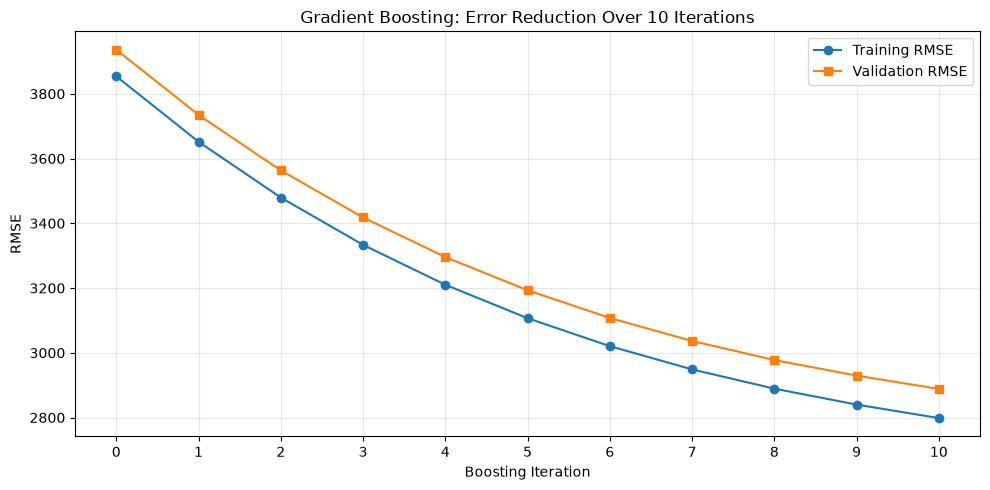

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    results["Iteration"],
    results["Train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    results["Iteration"],
    results["Validation_RMSE"],
    marker="s",
    label="Validation RMSE"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("RMSE")
plt.title("Gradient Boosting: Error Reduction Over 10 Iterations")
plt.xticks(range(n_iterations + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

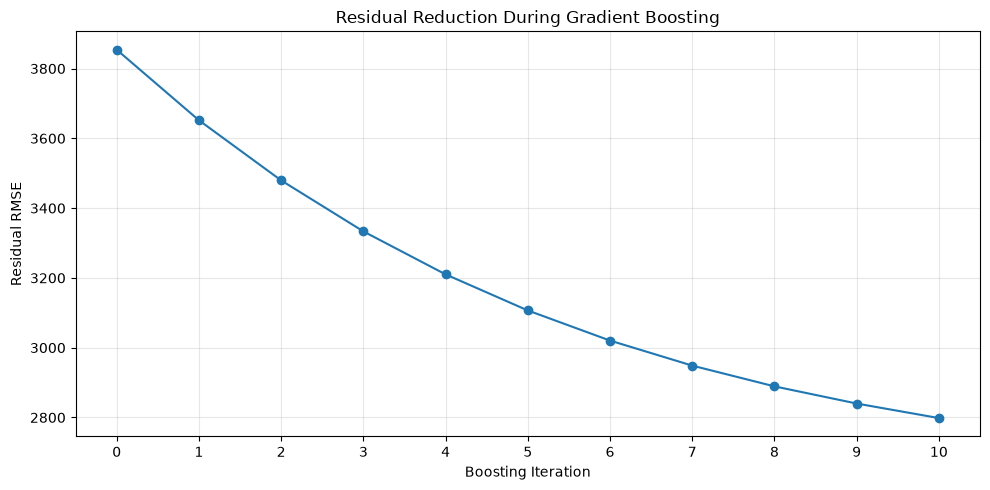

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    results["Iteration"],
    results["Residual_RMSE"],
    marker="o"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Residual RMSE")
plt.title("Residual Reduction During Gradient Boosting")
plt.xticks(range(n_iterations + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

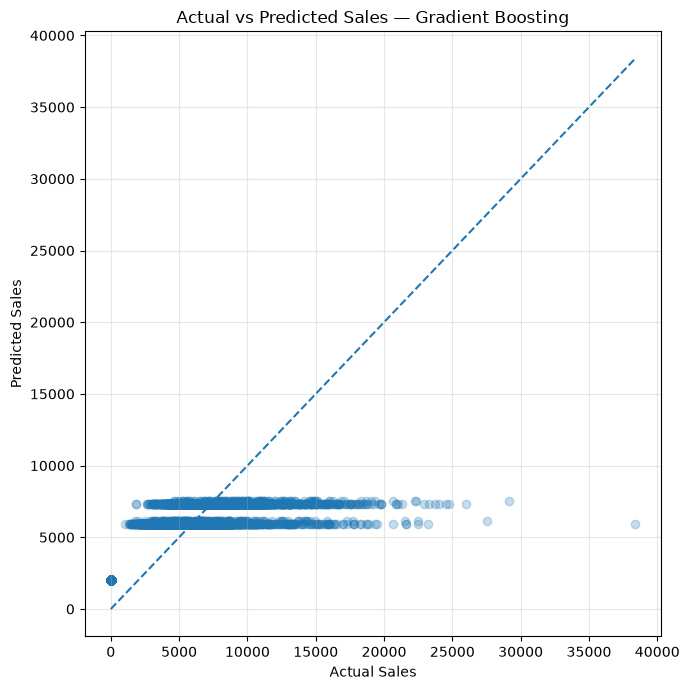

In [13]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    val_predictions,
    alpha=0.25
)

lower = min(y_val.min(), val_predictions.min())
upper = max(y_val.max(), val_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales — Gradient Boosting")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
initial_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        np.full(len(y_val), initial_prediction)
    )
)

final_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

final_mae = mean_absolute_error(y_val, val_predictions)

rmse_improvement = (
    (initial_rmse - final_rmse) / initial_rmse
) * 100

print(f"Initial mean prediction: {initial_prediction:.2f}")
print(f"Initial validation RMSE: {initial_rmse:.2f}")
print(f"Final validation RMSE: {final_rmse:.2f}")
print(f"Final validation MAE: {final_mae:.2f}")
print(f"Validation RMSE improvement: {rmse_improvement:.2f}%")
print(f"Number of trees: {len(trees)}")
print(f"Learning rate: {learning_rate}")

Initial mean prediction: 5777.86
Initial validation RMSE: 3936.04
Final validation RMSE: 2888.34
Final validation MAE: 2089.87
Validation RMSE improvement: 26.62%
Number of trees: 10
Learning rate: 0.1


In [15]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterGrid
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 0.2],
    "max_depth": [3, 5]
}

experiment_results = []
best_gbr = None
best_rmse = float("inf")
best_params = None

for params in ParameterGrid(param_grid):

    model = GradientBoostingRegressor(
        **params,
        random_state=42,
        loss="squared_error"
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    val_mae = mean_absolute_error(y_val, val_pred)
    val_r2 = r2_score(y_val, val_pred)

    experiment_results.append({
        **params,
        "Train_RMSE": train_rmse,
        "Validation_RMSE": val_rmse,
        "Validation_MAE": val_mae,
        "Validation_R2": val_r2
    })

    if val_rmse < best_rmse:
        best_rmse = val_rmse
        best_gbr = model
        best_params = params

# Display all experiments
gbr_results = pd.DataFrame(experiment_results)
gbr_results = gbr_results.sort_values("Validation_RMSE")

display(gbr_results.round(2))

print("Best parameters:", best_params)
print("Best validation RMSE:", round(best_rmse, 2))

,learning_rate,max_depth,n_estimators,Train_RMSE,Validation_RMSE,Validation_MAE,Validation_R2
17,0.20,5,200,1431.18,1653.23,1149.71,0.82
16,0.20,5,100,1769.60,1945.44,1339.75,0.76
11,0.10,5,200,1802.00,1975.73,1359.12,0.75
14,0.20,3,200,1927.46,2046.87,1426.94,0.73
15,0.20,5,50,2058.80,2203.32,1494.28,0.69
10,0.10,5,100,2065.00,2205.99,1492.91,0.69
13,0.20,3,100,2169.79,2284.88,1545.44,0.66
8,0.10,3,200,2174.34,2286.08,1547.96,0.66
9,0.10,5,50,2283.32,2411.51,1600.51,0.62
12,0.20,3,50,2311.05,2415.87,1619.25,0.62


Best parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200}
Best validation RMSE: 1653.23


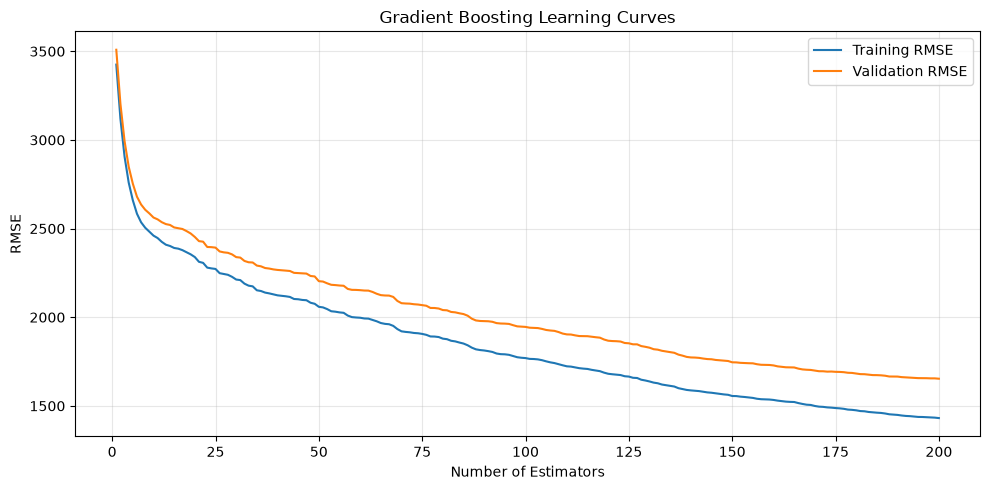

In [17]:
train_errors = []
val_errors = []

for train_pred in best_gbr.staged_predict(X_train):
    train_errors.append(
        np.sqrt(mean_squared_error(y_train, train_pred))
    )

for val_pred in best_gbr.staged_predict(X_val):
    val_errors.append(
        np.sqrt(mean_squared_error(y_val, val_pred))
    )

iterations = range(1, len(train_errors) + 1)

plt.figure(figsize=(10, 5))

plt.plot(iterations, train_errors, label="Training RMSE")
plt.plot(iterations, val_errors, label="Validation RMSE")

plt.xlabel("Number of Estimators")
plt.ylabel("RMSE")
plt.title("Gradient Boosting Learning Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
lr_models = {
    "LR=0.1, Trees=100": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "LR=0.01, Trees=500": GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.01,
        max_depth=3,
        random_state=42
    )
}

lr_results = []

for name, model in lr_models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    lr_results.append({
        "Model": name,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_val, val_pred)
        ),
        "Validation_MAE": mean_absolute_error(y_val, val_pred),
        "Validation_R2": r2_score(y_val, val_pred)
    })

lr_comparison = pd.DataFrame(lr_results)
display(lr_comparison.round(2))

,Model,Train_RMSE,Validation_RMSE,Validation_MAE,Validation_R2
0,"LR=0.1, Trees=100",2321.16,2425.15,1625.27,0.62
1,"LR=0.01, Trees=500",2440.26,2537.67,1678.11,0.58


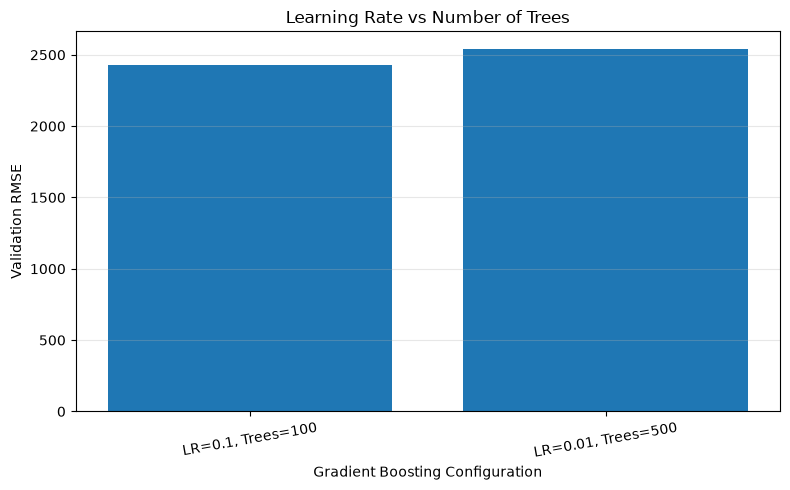

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    lr_comparison["Model"],
    lr_comparison["Validation_RMSE"]
)

plt.xlabel("Gradient Boosting Configuration")
plt.ylabel("Validation RMSE")
plt.title("Learning Rate vs Number of Trees")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

comparison_models = {
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": best_gbr
}

for name, model in comparison_models.items():
    model.fit(X_train, y_train)
    print(name, "training completed")

Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


In [21]:
comparison_results = []
model_predictions = {}

for name, model in comparison_models.items():

    predictions = model.predict(X_val)
    model_predictions[name] = predictions

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)
    r2 = r2_score(y_val, predictions)

    comparison_results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2_Score": r2
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values("RMSE")

display(comparison_df.round(3))

print("Best model based on validation RMSE:")
print(comparison_df.iloc[0]["Model"])

,Model,RMSE,MAE,R2_Score
2,Gradient Boosting,1653.232,1149.710,0.824
1,Random Forest,2566.264,1662.879,0.575
0,Decision Tree,2592.979,1661.069,0.566


Best model based on validation RMSE:
Gradient Boosting


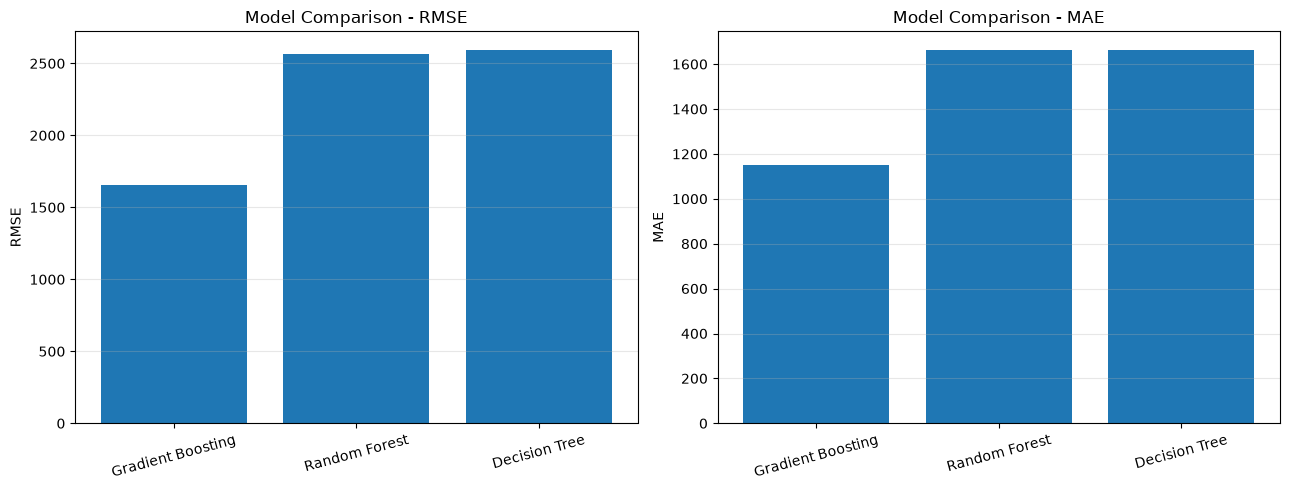

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    comparison_df["Model"],
    comparison_df["RMSE"]
)
axes[0].set_title("Model Comparison - RMSE")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    comparison_df["Model"],
    comparison_df["MAE"]
)
axes[1].set_title("Model Comparison - MAE")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

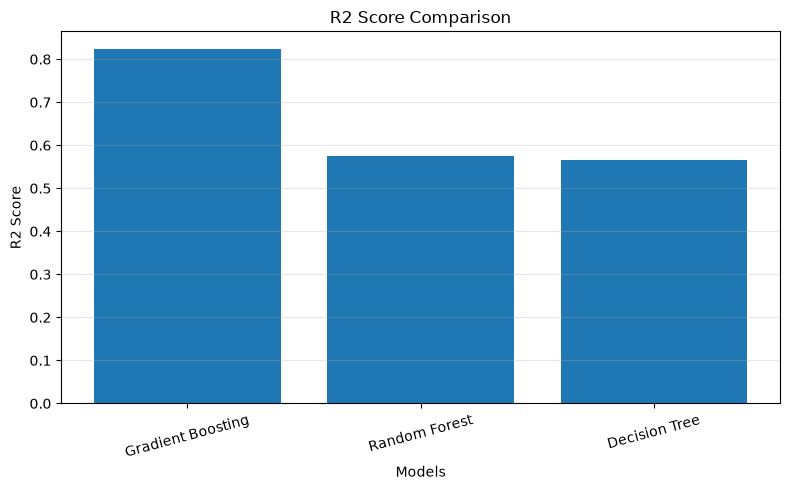

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["R2_Score"]
)

plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.title("R2 Score Comparison")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
importance_data = pd.DataFrame({
    "Feature": X_train.columns
})

for name, model in comparison_models.items():
    importance_data[name] = model.feature_importances_

display(
    importance_data.sort_values(
        "Gradient Boosting",
        ascending=False
    ).round(4)
)

,Feature,Decision Tree,Random Forest,Gradient Boosting
2,Open,0.7387,0.3883,0.5567
0,Store,0.0442,0.0346,0.2574
3,Promo,0.1151,0.1729,0.0899
1,DayOfWeek,0.0336,0.2686,0.0353
8,WeekOfYear,0.0289,0.0268,0.0272
7,Day,0.0284,0.0247,0.0222
6,Month,0.0077,0.0154,0.0059
5,Year,0.0014,0.0038,0.0033
4,SchoolHoliday,0.0020,0.0047,0.0015
10,StateHoliday_a,0.0000,0.0167,0.0002


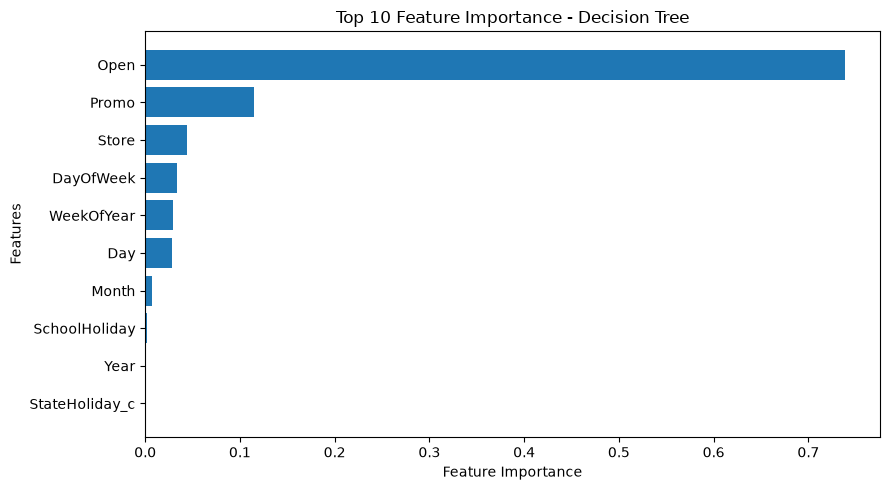

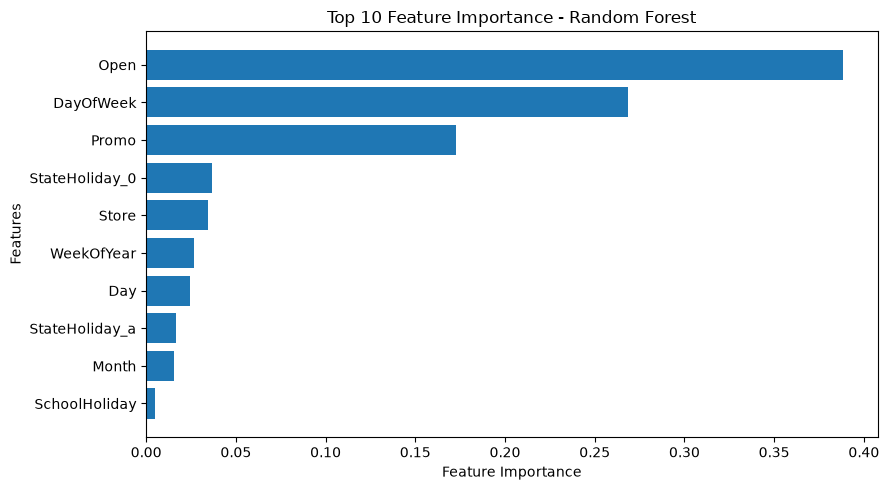

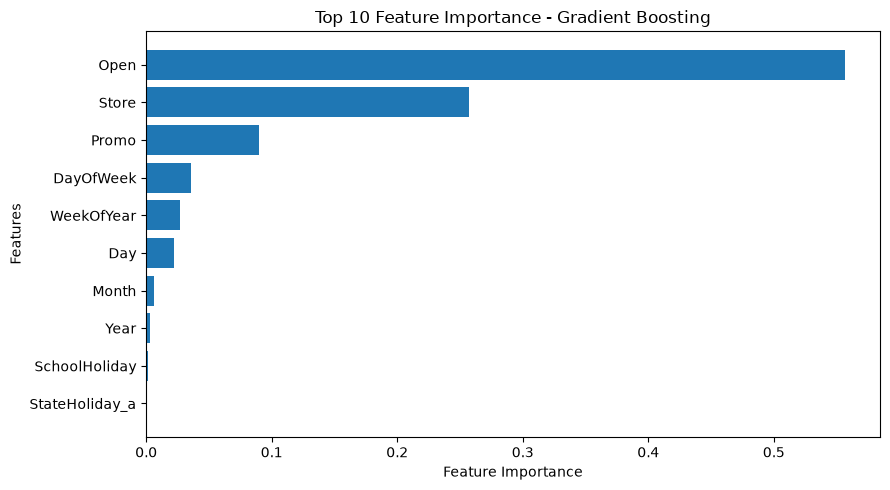

In [25]:
for model_name in comparison_models.keys():

    top_features = importance_data.sort_values(
        model_name,
        ascending=False
    ).head(10)

    plt.figure(figsize=(9, 5))

    plt.barh(
        top_features["Feature"],
        top_features[model_name]
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Features")
    plt.title(f"Top 10 Feature Importance - {model_name}")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

In [26]:
model_names = list(comparison_models.keys())

for model_name in model_names:
    importance_data[model_name + "_Rank"] = (
        importance_data[model_name]
        .rank(ascending=False, method="average")
    )

rank_columns = [name + "_Rank" for name in model_names]

importance_data["Average_Rank"] = importance_data[
    rank_columns
].mean(axis=1)

consistent_features = importance_data.sort_values(
    "Average_Rank"
)

display(
    consistent_features[
        ["Feature"] + model_names + ["Average_Rank"]
    ].head(10).round(4)
)

,Feature,Decision Tree,Random Forest,Gradient Boosting,Average_Rank
2,Open,0.7387,0.3883,0.5567,1.0000
3,Promo,0.1151,0.1729,0.0899,2.6667
1,DayOfWeek,0.0336,0.2686,0.0353,3.3333
0,Store,0.0442,0.0346,0.2574,3.3333
8,WeekOfYear,0.0289,0.0268,0.0272,5.3333
7,Day,0.0284,0.0247,0.0222,6.3333
6,Month,0.0077,0.0154,0.0059,7.6667
4,SchoolHoliday,0.0020,0.0047,0.0015,9.0000
9,StateHoliday_0,0.0000,0.0368,0.0002,9.0000
5,Year,0.0014,0.0038,0.0033,9.6667


In [27]:
best_model_name = comparison_df.iloc[0]["Model"]

print("MODEL COMPARISON CONCLUSION")
print("---------------------------")

print("Best model:", best_model_name)

print(
    "Validation RMSE:",
    round(comparison_df.iloc[0]["RMSE"], 2)
)

print(
    "Validation MAE:",
    round(comparison_df.iloc[0]["MAE"], 2)
)

print(
    "Validation R2:",
    round(comparison_df.iloc[0]["R2_Score"], 4)
)

print("\nRecommendation:")

if best_model_name == "Decision Tree":
    print("Decision Tree provides the best validation accuracy and is relatively easy to interpret.")
elif best_model_name == "Random Forest":
    print("Random Forest provides the best validation accuracy by combining multiple decision trees.")
else:
    print("Gradient Boosting provides the best validation accuracy by sequentially correcting prediction errors.")

MODEL COMPARISON CONCLUSION
---------------------------
Best model: Gradient Boosting
Validation RMSE: 1653.23
Validation MAE: 1149.71
Validation R2: 0.8236

Recommendation:
Gradient Boosting provides the best validation accuracy by sequentially correcting prediction errors.


In [ ]:
gbr_results.to_csv(
    "gradient_boosting_parameter_results.csv",
    index=False
)

lr_comparison.to_csv(
    "learning_rate_comparison.csv",
    index=False
)

comparison_df.to_csv(
    "tree_model_comparison.csv",
    index=False
)

importance_data.to_csv(
    "feature_importance_comparison.csv",
    index=False
)

All Part B and Part C results saved successfully!
